In [1]:
from google.colab import files
uploaded = files.upload()


Saving diabetes (6).csv to diabetes (6).csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [4]:
df = pd.read_csv("diabetes (6).csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Separate input and output
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Dataset Shape: (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [5]:
print("\n================ KNN CLASSIFIER ================")

k_values = [1, 3, 5, 7, 9, 11, 15, 20]

accuracy_values = []

for k in k_values:

    knn_classifier = KNeighborsClassifier(n_neighbors=k)

    knn_classifier.fit(X_train_scaled, y_train)

    y_pred = knn_classifier.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    accuracy_values.append(accuracy)

    print("K =", k, "Accuracy =", round(accuracy, 4))


# Find best K
best_k = k_values[np.argmax(accuracy_values)]

print("\nBest K for Classification:", best_k)
print("Best Accuracy:", round(max(accuracy_values), 4))


# Train final classifier
knn_classifier = KNeighborsClassifier(n_neighbors=best_k)

knn_classifier.fit(X_train_scaled, y_train)

y_pred = knn_classifier.predict(X_test_scaled)


# Classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


================ KNN CLASSIFIER ================
K = 1 Accuracy = 0.7078
K = 3 Accuracy = 0.6948
K = 5 Accuracy = 0.7013
K = 7 Accuracy = 0.7468
K = 9 Accuracy = 0.7338
K = 11 Accuracy = 0.7208
K = 15 Accuracy = 0.7532
K = 20 Accuracy = 0.7338

Best K for Classification: 15
Best Accuracy: 0.7532

Classification Metrics:
Accuracy  : 0.7532
Precision : 0.6667
Recall    : 0.5926
F1 Score  : 0.6275

Confusion Matrix:
[[84 16]
 [22 32]]


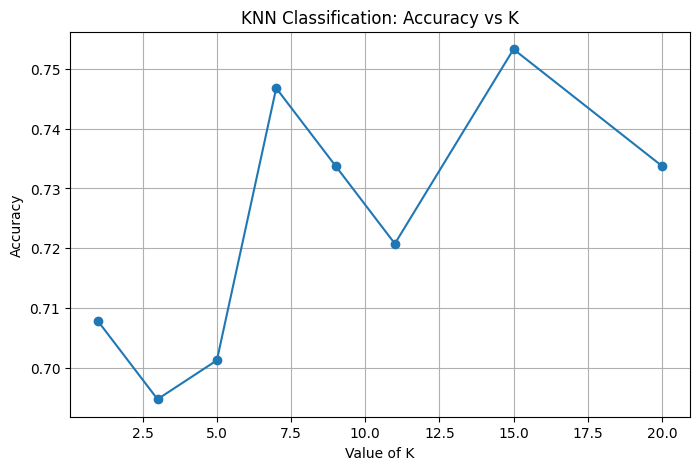

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("Value of K")
plt.ylabel("Accuracy")
plt.title("KNN Classification: Accuracy vs K")
plt.grid(True)

plt.show()

In [7]:
print("\n================ KNN REGRESSOR ================")

# For regression, use Glucose as the target.
# The remaining columns are used as input features.

X_reg = df.drop("Glucose", axis=1)
y_reg = df["Glucose"]

# Remove Outcome from regression features
X_reg = X_reg.drop("Outcome", axis=1)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# Scaling
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)


# Different K values
reg_k_values = [1, 3, 5, 7, 9, 11, 15, 20]

r2_values = []

for k in reg_k_values:

    knn_regressor = KNeighborsRegressor(n_neighbors=k)

    knn_regressor.fit(
        X_train_reg_scaled,
        y_train_reg
    )

    y_reg_pred = knn_regressor.predict(
        X_test_reg_scaled
    )

    r2 = r2_score(y_test_reg, y_reg_pred)

    r2_values.append(r2)

    print("K =", k, "R² Score =", round(r2, 4))


# Best K
best_reg_k = reg_k_values[np.argmax(r2_values)]

print("\nBest K for Regression:", best_reg_k)
print("Best R² Score:", round(max(r2_values), 4))


# Final KNN Regressor
knn_regressor = KNeighborsRegressor(
    n_neighbors=best_reg_k
)

knn_regressor.fit(
    X_train_reg_scaled,
    y_train_reg
)

y_reg_pred = knn_regressor.predict(
    X_test_reg_scaled
)


# Regression metrics
mae = mean_absolute_error(
    y_test_reg,
    y_reg_pred
)

mse = mean_squared_error(
    y_test_reg,
    y_reg_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_reg,
    y_reg_pred
)

print("\nRegression Metrics:")
print("MAE  :", round(mae, 4))
print("MSE  :", round(mse, 4))
print("RMSE :", round(rmse, 4))
print("R²   :", round(r2, 4))


================ KNN REGRESSOR ================
K = 1 R² Score = -0.2924
K = 3 R² Score = -0.1041
K = 5 R² Score = -0.0197
K = 7 R² Score = 0.0894
K = 9 R² Score = 0.0807
K = 11 R² Score = 0.1189
K = 15 R² Score = 0.1266
K = 20 R² Score = 0.131

Best K for Regression: 20
Best R² Score: 0.131

Regression Metrics:
MAE  : 23.7042
MSE  : 874.5043
RMSE : 29.572
R²   : 0.131


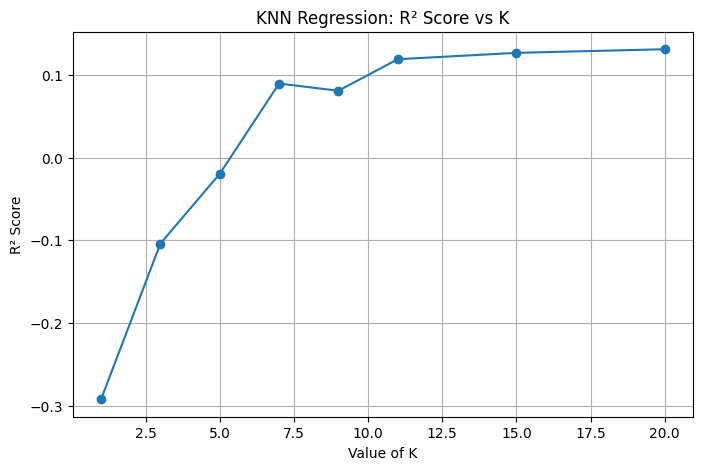

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    reg_k_values,
    r2_values,
    marker="o"
)

plt.xlabel("Value of K")
plt.ylabel("R² Score")
plt.title("KNN Regression: R² Score vs K")
plt.grid(True)

plt.show()

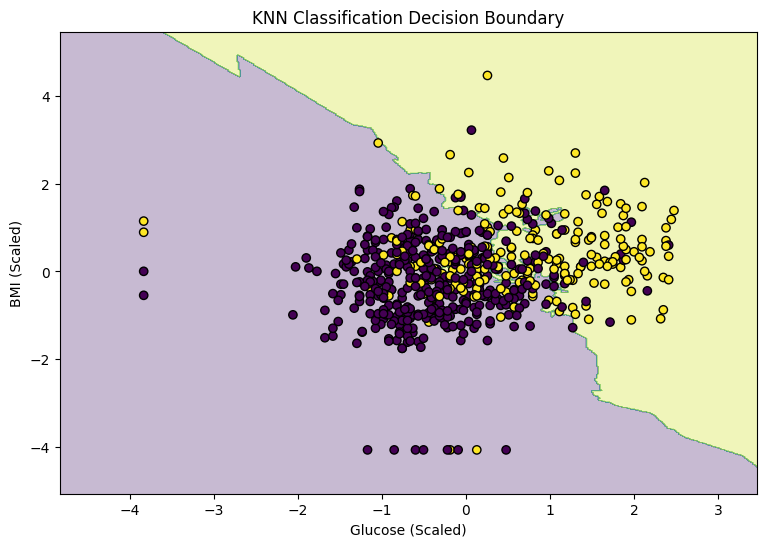

In [9]:
X_boundary = df[["Glucose", "BMI"]]
y_boundary = df["Outcome"]

# Split data
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_boundary,
    y_boundary,
    test_size=0.2,
    random_state=42,
    stratify=y_boundary
)

# Scale the two features
boundary_scaler = StandardScaler()

Xb_train_scaled = boundary_scaler.fit_transform(Xb_train)
Xb_test_scaled = boundary_scaler.transform(Xb_test)


# Train KNN
boundary_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

boundary_knn.fit(
    Xb_train_scaled,
    yb_train
)


# Create mesh grid
x_min = Xb_train_scaled[:, 0].min() - 1
x_max = Xb_train_scaled[:, 0].max() + 1

y_min = Xb_train_scaled[:, 1].min() - 1
y_max = Xb_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)


# Predict every point in grid
grid_points = np.c_[xx.ravel(), yy.ravel()]

Z = boundary_knn.predict(grid_points)

Z = Z.reshape(xx.shape)


# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3
)

plt.scatter(
    Xb_train_scaled[:, 0],
    Xb_train_scaled[:, 1],
    c=yb_train,
    edgecolors="black"
)

plt.xlabel("Glucose (Scaled)")
plt.ylabel("BMI (Scaled)")
plt.title("KNN Classification Decision Boundary")

plt.show()


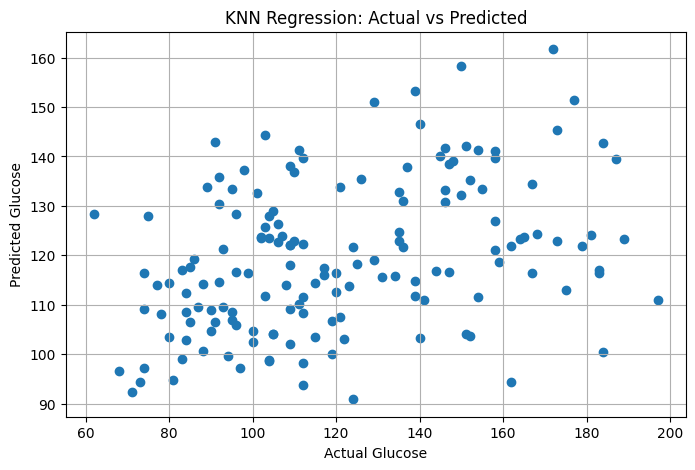

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_reg,
    y_reg_pred
)

plt.xlabel("Actual Glucose")
plt.ylabel("Predicted Glucose")
plt.title("KNN Regression: Actual vs Predicted")

plt.grid(True)

plt.show()